In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [18]:
df = pd.read_csv('data_science_job.csv')

In [19]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [20]:
df.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [21]:
df.shape

(19158, 13)

In [22]:
cols = [var for var in df.columns if df[var].isnull().mean() < 0.05 and df[var].isnull().mean() > 0]
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [23]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
3947,0.740,Full time course,High School,3.0,160.0
7052,NaN,no_enrollment,Graduate,8.0,9.0
6781,0.794,Part time course,Graduate,1.0,9.0
17878,0.926,no_enrollment,Graduate,13.0,17.0
10604,0.920,no_enrollment,Graduate,20.0,53.0


In [24]:
len(df[cols].dropna())/len(df) # missing value columns hatane pe kitna data bacha hai

0.8968577095730244

In [1]:
new_df = df[cols].dropna()
df.shape, new_df.shapenew_df 

NameError: name 'df' is not defined

array([[<Axes: title={'center': 'city_development_index'}>,
        <Axes: title={'center': 'experience'}>],
       [<Axes: title={'center': 'training_hours'}>, <Axes: >]],
      dtype=object)

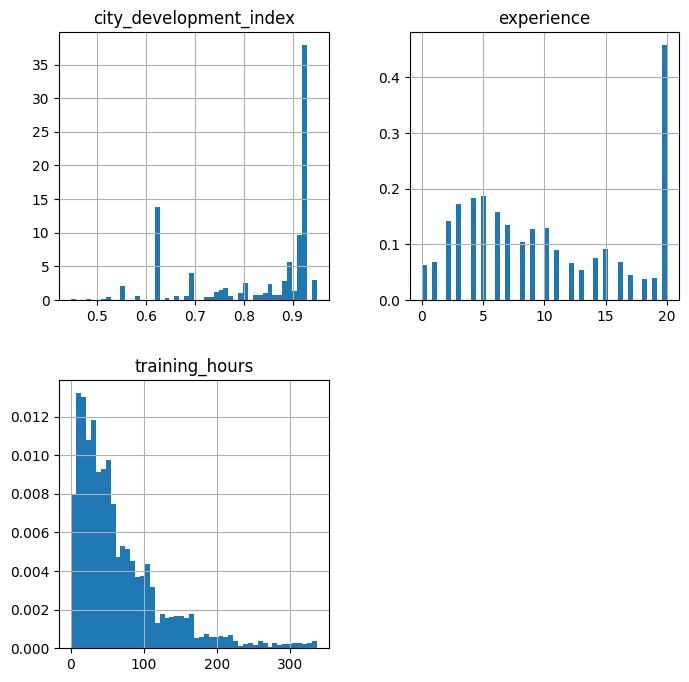

In [29]:
new_df.hist(bins=50, density=True, figsize=(8, 8))

In [30]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
15040,0.903,no_enrollment,Graduate,20.0,80.0
13972,0.624,no_enrollment,Graduate,12.0,8.0
10099,0.887,no_enrollment,Graduate,20.0,139.0
14543,0.550,no_enrollment,Graduate,4.0,52.0
9837,0.910,no_enrollment,Graduate,20.0,46.0


<Axes: >

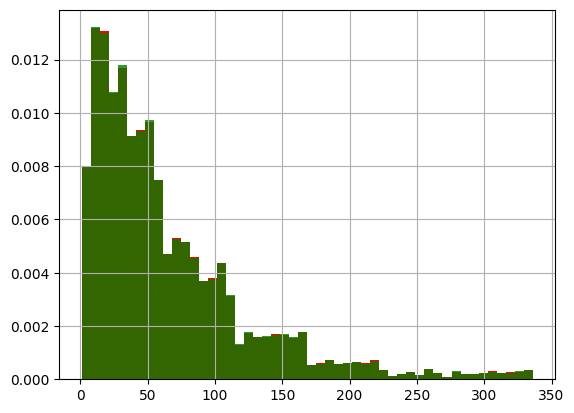

In [32]:
fig = plt.figure()
ax = fig.add_subplot(111)

#Original data
df['training_hours'].hist( bins=50, density=True, ax=ax, color = 'red')

# data after cca, the argument alpha makes the color transparent, so we can
# see the overlay of the 2 distributions
new_df['training_hours'].hist( bins=50, density=True, ax=ax, alpha=0.8, color = 'green')


<Axes: ylabel='Density'>

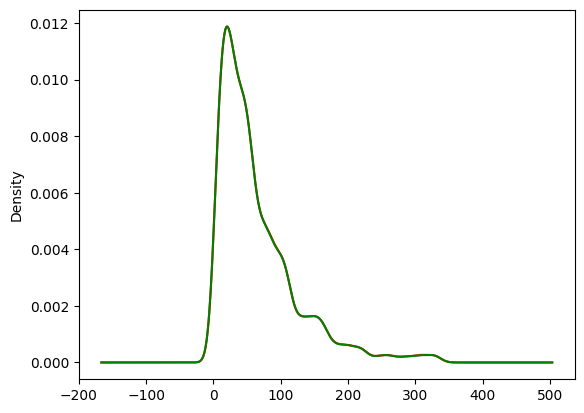

In [36]:
fig = plt.figure()
ax = fig.add_subplot(111)

# data before cca
df['training_hours'].plot.density(ax=ax, color = 'red')

#data after cca
new_df['training_hours'].plot.density(ax=ax, color = 'green')

In [37]:
new_df.sample(2)

,city_development_index,enrolled_university,education_level,experience,training_hours
6988,0.920,no_enrollment,Masters,14.0,25.0
4588,0.776,no_enrollment,Graduate,5.0,4.0


<Axes: >

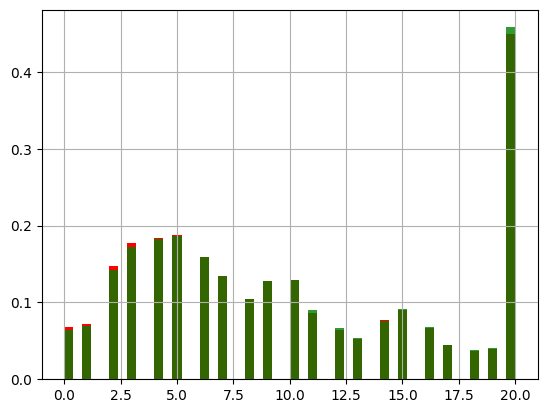

In [38]:
fig = plt.figure()
ax = fig.add_subplot(111)

# Before cca
df['experience'].hist(bins=50, density=True, ax=ax, color = 'red')

#After cca
new_df['experience'].hist(bins=50, density=True, ax=ax, alpha=0.8, color = 'green')



<Axes: ylabel='Density'>

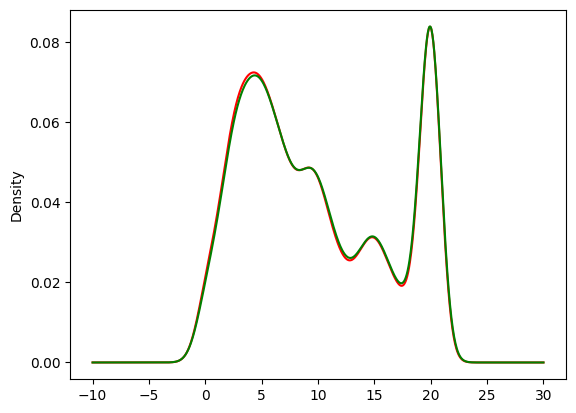

In [39]:
fig = plt.figure()
ax = fig.add_subplot(111)

#Before cca
df['experience'].plot.density(ax=ax, color = 'red')

#After cca
new_df['experience'].plot.density(ax=ax, color = 'green')

<Axes: >

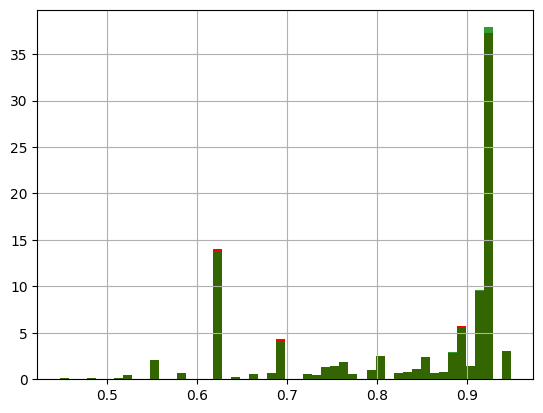

In [40]:
fig = plt.figure()
ax = fig.add_subplot(111)

#Before cca
df['city_development_index'].hist(bins=50, density=True, ax=ax, color='red')

#After cca
new_df['city_development_index'].hist(bins=50, density=True, ax=ax, alpha=0.8, color='green')

<Axes: ylabel='Density'>

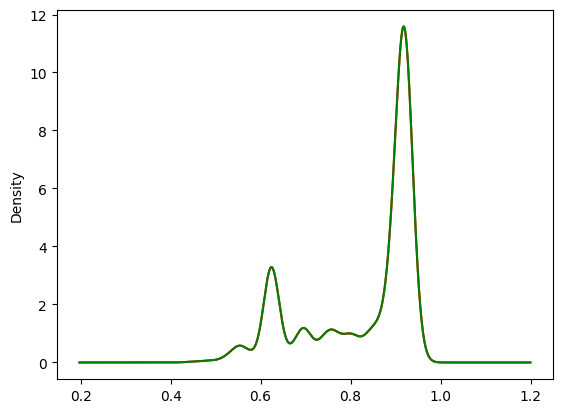

In [41]:
fig = plt.figure()
ax = fig.add_subplot(111)

#Before cca
df['city_development_index'].plot.density(ax=ax, color='red')

#After cca
df['city_development_index'].plot.density(ax=ax, color='green')

In [42]:
new_df.sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
18718,0.897,no_enrollment,Masters,20.0,39.0
14361,0.890,no_enrollment,Graduate,17.0,96.0
15592,0.910,no_enrollment,Masters,20.0,16.0
415,0.920,Full time course,Graduate,1.0,53.0
11609,0.899,no_enrollment,Graduate,2.0,37.0


In [50]:
temp = pd.concat([
    # percentage of observations per category, original data
    df['enrolled_university'].value_counts()/len(df),

    # percentage of observations per category, cca data
    new_df['enrolled_university'].value_counts()/len(new_df)],
    axis=1
)

temp.columns = ['original', 'cca']

temp

,original,cca
enrolled_university,,
no_enrollment,0.721213,0.735188
Full time course,0.196106,0.200733
Part time course,0.062533,0.064079


In [51]:
temp = pd.concat([
    # percentage of observations per category, original data
    df['education_level'].value_counts()/len(df),

    # percentage of observations per category, cca data
    new_df['education_level'].value_counts()/len(new_df)],
    axis=1
)

temp.columns = ['original', 'cca']

temp

,original,cca
education_level,,
Graduate,0.605387,0.619835
Masters,0.227633,0.234082
High School,0.105282,0.107380
Phd,0.021610,0.022116
Primary School,0.016077,0.016587
